# Partycjonowanie A/B/C — szybsze przygotowanie

A: jeden Parquet. B: K grup stacji. C: dokładnie 3K grup stacji. Tylko A/B/C, bez dodatkowych wariantów bez filtra.

Zapis przez PyArrow (Snappy, wspólne ustawienia statystyk i grup wierszy). Zachowano raporty, porównania i trzy wykresy.

Skala N tworzy N kopii źródła z suffixem __copy_NNN w kod_stacji, bez zmiany dat i pozostałych wartości. Przy 1x kody pozostają oryginalne.

Przy pierwszym uruchomieniu przygotowanie nadal wymaga zapisania A/B/C. Kolejne przebiegi mogą użyć gotowych danych. Przygotowanie nie wchodzi do czasu zapytań.

Benchmark jest osobnym eksperymentem na wycinku 2024. Skalowanie kopiuje stacje (nowe identyfikatory), zachowując daty i wartości; nie symuluje kolejnych lat. Analizy korzystają z rzeczywistych danych 2023–2025.

## 1. Konfiguracja

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from uuid import uuid4
import runpy
import json
import polars as pl
from IPython.display import display, Markdown

PROJECT_ROOT = None  # np. r"D:/gios-bigdata"; None = automatyczne wyszukiwanie
SOURCE_PATH = "data/silver/pm25_pogoda_2024.parquet"  # względem projektu lub absolutna
SCALE_FACTORS = [1, 10]  # [1], [10] lub [1, 10]
RUN_LABEL = "partition_test"
GROUP_COUNT = 8  # B=8, C=24
SCENARIO_SIZES = [1, 8, 32]  # dodatkowo zawsze wszystkie stacje
REPEATS = 20
WARMUPS = 3
THREADS = None  # None = maksymalnie 4
ROW_GROUP_SIZE = 122880
WRITE_STATISTICS = False
READER_MODE = "all_files_list"  # lub "glob"
SEED = 42
SMALL_DIFFERENCE_PERCENT = 5.0
MEMORY_LIMIT = None  # np. "4GB"; dotyczy tylko DuckDB
SHOW_PLOTS = True
VALIDATION_MODE = "quick"  # "full" = klucze + pełne EXCEPT ALL + kontrola przypisania grup
REUSE_PREPARED_DATA = True  # False = nowe przygotowanie danych dla każdego przebiegu
GENERATE_PLOTS = True


## 2. Projekt i kontrola konfiguracji

In [2]:
def find_root(start):
    start = Path(start).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "scripts/partition_benchmark.py").is_file():
            return candidate
    raise FileNotFoundError("Nie znaleziono scripts/partition_benchmark.py")

ROOT = find_root(PROJECT_ROOT if PROJECT_ROOT is not None else Path.cwd())
benchmark = runpy.run_path(str(ROOT / "scripts/partition_benchmark.py"))
if not SCALE_FACTORS or any(type(n) is not int or n < 1 for n in SCALE_FACTORS):
    raise ValueError("SCALE_FACTORS musi zawierać dodatnie liczby całkowite")
if len(set(SCALE_FACTORS)) != len(SCALE_FACTORS):
    raise ValueError("Powtórzone skale")
source = Path(SOURCE_PATH)
source = source if source.is_absolute() else ROOT / source
if not source.is_file():
    raise FileNotFoundError(f"Najpierw wykonaj notebook 06: {source}")

SETTINGS = dict(root=ROOT, source_path=source, repeats=REPEATS, warmups=WARMUPS,
    threads=THREADS, group_count=GROUP_COUNT, row_group_size=ROW_GROUP_SIZE,
    write_statistics=WRITE_STATISTICS, reader_mode=READER_MODE, seed=SEED,
    scenario_sizes=SCENARIO_SIZES, small_difference_percent=SMALL_DIFFERENCE_PERCENT,
    memory_limit=MEMORY_LIMIT, run_label=RUN_LABEL,
    validation_mode=VALIDATION_MODE,reuse_prepared_data=REUSE_PREPARED_DATA,
    generate_plots=GENERATE_PLOTS)
def rel(path):
    path = Path(path).resolve()
    return path.relative_to(ROOT).as_posix() if path.is_relative_to(ROOT) else path.name

print("Projekt:", ROOT.name)
print("Źródło:", rel(source))
print("Skale:", SCALE_FACTORS)
print(f"B={GROUP_COUNT}, C={3*GROUP_COUNT}; walidacja={VALIDATION_MODE}; cache={REUSE_PREPARED_DATA}")


Projekt: D:\Projekty\gios-bigdata
Źródło: D:\Projekty\gios-bigdata\data\silver\pm25_pogoda_2024.parquet
Skale: [1, 10]
B=8, C=24; walidacja=quick; cache=True


## 3. Uruchomienie
Tryb quick porównuje schematy i liczby rekordów ze stopek Parquet, bez pełnego skanowania wszystkich wartości i kluczy. Zgodność wyników każdego zapytania A/B/C jest sprawdzana poza timerem.
Tryb full dodatkowo sprawdza unikalność kluczy, przypisania grup i wszystkie wartości przez dwukierunkowe EXCEPT ALL — jest znacznie kosztowniejszy.
Plany są tworzone przez EXPLAIN, bez dodatkowego uruchamiania zapytań przez EXPLAIN ANALYZE.
Cache systemowy nie jest czyszczony. Kolejność pomiarów jest losowana. Czas pomiaru obejmuje execute + fetchall.


In [3]:
results = []
for scale in SCALE_FACTORS:
    print(f"Start: skala {scale}×")
    result = benchmark["run_experiment"](scale_factor=scale, **SETTINGS)
    results.append(result)
    print("Wiersze:", result["scaling"]["actual_rows"])
    print("Raport:", rel(result["report"]))
    print("Użyto cache:", result["reused"])
    print("Etapy [s]:", result["stage_times"])
    display(result["summary"])
    display(result["storage"])

Start: skala 1×
SHA-256 zrodla: pierwszy odczyt lub zmieniony plik
Przygotowanie zrodla 1x
Zapis lub odczyt cache A/B/C
OK: Zapis lub odczyt cache A/B/C (6.64 s)
Walidacja quick
OK: Walidacja quick (0.10 s)
Scenariusze i EXPLAIN
OK: Scenariusze i EXPLAIN (0.44 s)
Benchmark
Powtorzenie 1/20
Powtorzenie 2/20
Powtorzenie 3/20
Powtorzenie 4/20
Powtorzenie 5/20
Powtorzenie 6/20
Powtorzenie 7/20
Powtorzenie 8/20
Powtorzenie 9/20
Powtorzenie 10/20
Powtorzenie 11/20
Powtorzenie 12/20
Powtorzenie 13/20
Powtorzenie 14/20
Powtorzenie 15/20
Powtorzenie 16/20
Powtorzenie 17/20
Powtorzenie 18/20
Powtorzenie 19/20
Powtorzenie 20/20
OK: Benchmark (6.18 s)
Wiersze: 843264
Raport: D:\Projekty\gios-bigdata\reports\partition_benchmark\partition_test_x1_20261124T203347_904875Z_debd34ba
Użyto cache: False
Etapy [s]: {'Zapis lub odczyt cache A/B/C': 6.64047, 'Walidacja quick': 0.0967915, 'Scenariusze i EXPLAIN': 0.4355762, 'Benchmark': 6.1815656}


id,scenario,variant,scope,repeats,mean_ms,median_ms,std_ms,min_ms,max_ms
str,str,str,str,i64,f64,f64,f64,f64,f64
"""q01""","""1_stacji""","""A""","""selected""",20,9.961875,9.8159,1.21605,8.2517,12.3092
"""q01""","""1_stacji""","""B""","""selected""",20,9.427865,8.32155,2.473224,7.6341,17.9441
"""q01""","""1_stacji""","""C""","""selected""",20,10.81323,10.23685,1.455304,9.2479,14.0289
"""q02""","""8_stacji""","""A""","""selected""",20,23.95131,23.3654,2.831429,20.3778,29.1871
"""q02""","""8_stacji""","""B""","""selected""",20,21.74942,22.5229,2.42194,18.2271,25.854
…,…,…,…,…,…,…,…,…,…
"""q03""","""32_stacji""","""B""","""selected""",20,30.23949,29.81615,2.535553,25.3892,35.0848
"""q03""","""32_stacji""","""C""","""selected""",20,33.17471,33.0406,3.585575,27.5133,41.1073
"""control""","""wszystkie_stacje""","""A""","""all""",20,21.82872,22.11325,3.372278,16.8314,27.2839


variant,files,rows,bytes,row_groups
str,i64,i64,i64,i64
"""A""",1,843264,30969556,7
"""B""",8,843264,31750332,8
"""C""",24,843264,36698355,24


Start: skala 10×
Przygotowanie zrodla 10x
Zapis lub odczyt cache A/B/C
OK: Zapis lub odczyt cache A/B/C (75.89 s)
Walidacja quick
OK: Walidacja quick (0.37 s)
Scenariusze i EXPLAIN
OK: Scenariusze i EXPLAIN (1.50 s)
Benchmark
Powtorzenie 1/20
Powtorzenie 2/20
Powtorzenie 3/20
Powtorzenie 4/20
Powtorzenie 5/20
Powtorzenie 6/20
Powtorzenie 7/20
Powtorzenie 8/20
Powtorzenie 9/20
Powtorzenie 10/20
Powtorzenie 11/20
Powtorzenie 12/20
Powtorzenie 13/20
Powtorzenie 14/20
Powtorzenie 15/20
Powtorzenie 16/20
Powtorzenie 17/20
Powtorzenie 18/20
Powtorzenie 19/20
Powtorzenie 20/20
OK: Benchmark (27.41 s)
Wiersze: 8432640
Raport: D:\Projekty\gios-bigdata\reports\partition_benchmark\partition_test_x10_20261124T203404_495873Z_9b40de70
Użyto cache: False
Etapy [s]: {'Zapis lub odczyt cache A/B/C': 75.8938132, 'Walidacja quick': 0.367038, 'Scenariusze i EXPLAIN': 1.50052, 'Benchmark': 27.4118711}


id,scenario,variant,scope,repeats,mean_ms,median_ms,std_ms,min_ms,max_ms
str,str,str,str,i64,f64,f64,f64,f64,f64
"""q01""","""1_stacji""","""A""","""selected""",20,29.00734,28.26305,2.909474,24.3331,35.7486
"""q01""","""1_stacji""","""B""","""selected""",20,12.72649,12.19065,2.691337,10.2765,22.4321
"""q01""","""1_stacji""","""C""","""selected""",20,12.1559,11.86375,1.432821,10.5298,16.7253
"""q02""","""8_stacji""","""A""","""selected""",20,149.97392,145.7283,21.291861,131.638,231.2036
"""q02""","""8_stacji""","""B""","""selected""",20,91.336895,87.4189,12.828167,75.8232,133.4952
…,…,…,…,…,…,…,…,…,…
"""q03""","""32_stacji""","""B""","""selected""",20,139.42079,137.2544,12.329029,121.3125,177.1888
"""q03""","""32_stacji""","""C""","""selected""",20,120.742105,117.2194,11.481256,105.9891,151.3418
"""control""","""wszystkie_stacje""","""A""","""all""",20,142.88299,140.76015,11.266633,128.9432,168.9453


variant,files,rows,bytes,row_groups
str,i64,i64,i64,i64
"""A""",1,8432640,240831935,69
"""B""",8,8432640,301005171,72
"""C""",24,8432640,313078989,72


## 4. Łączne wyniki i porównanie

In [6]:
stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ") + "_" + uuid4().hex[:8]
suite_report = ROOT / "reports/partition_benchmark" / f"suite_{stamp}"
suite_report.mkdir(parents=True, exist_ok=False)
combined = pl.concat([
    r["summary"].with_columns(pl.lit(r["scale_factor"]).alias("scale_factor"))
    for r in results
])
combined.write_csv(suite_report / "all_scales_summary.csv")
all_storage = pl.concat([
    r["storage"].with_columns(pl.lit(r["scale_factor"]).alias("scale_factor"))
    for r in results
])
all_storage.write_csv(suite_report / "all_scales_storage.csv")
display(combined)

if 1 in SCALE_FACTORS and len(SCALE_FACTORS) > 1:
    keys = ["id", "scenario", "variant", "scope"]
    reference = combined.filter(pl.col("scale_factor") == 1).select(
        *keys, pl.col("median_ms").alias("median_ms_1x"),
        pl.col("mean_ms").alias("mean_ms_1x")
    )
    scaling_comparison = (
        combined.filter(pl.col("scale_factor") != 1)
        .join(reference, on=keys, how="left", validate="m:1")
        .with_columns(
            (pl.col("median_ms") / pl.col("median_ms_1x")).alias("median_time_ratio"),
            (pl.col("mean_ms") / pl.col("mean_ms_1x")).alias("mean_time_ratio")
        )
    )
    scaling_comparison.write_csv(suite_report / "scaling_comparison.csv")
    display(scaling_comparison)
else:
    print("Porównanie między skalami wymaga 1 i co najmniej jednej większej skali w SCALE_FACTORS.")

manifest = [{"scale_factor": r["scale_factor"], "report": str(r["report"]),
             "data": str(r["data"]), "scaling": r["scaling"]} for r in results]
(suite_report / "runs.json").write_text(
    json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
print("Raport zbiorczy:", rel(suite_report))

id,scenario,variant,scope,repeats,mean_ms,median_ms,std_ms,min_ms,max_ms,scale_factor
str,str,str,str,i64,f64,f64,f64,f64,f64,i32
"""q01""","""1_stacji""","""A""","""selected""",20,9.961875,9.8159,1.21605,8.2517,12.3092,1
"""q01""","""1_stacji""","""B""","""selected""",20,9.427865,8.32155,2.473224,7.6341,17.9441,1
"""q01""","""1_stacji""","""C""","""selected""",20,10.81323,10.23685,1.455304,9.2479,14.0289,1
"""q02""","""8_stacji""","""A""","""selected""",20,23.95131,23.3654,2.831429,20.3778,29.1871,1
"""q02""","""8_stacji""","""B""","""selected""",20,21.74942,22.5229,2.42194,18.2271,25.854,1
…,…,…,…,…,…,…,…,…,…,…
"""q03""","""32_stacji""","""B""","""selected""",20,139.42079,137.2544,12.329029,121.3125,177.1888,10
"""q03""","""32_stacji""","""C""","""selected""",20,120.742105,117.2194,11.481256,105.9891,151.3418,10
"""control""","""wszystkie_stacje""","""A""","""all""",20,142.88299,140.76015,11.266633,128.9432,168.9453,10


id,scenario,variant,scope,repeats,mean_ms,median_ms,std_ms,min_ms,max_ms,scale_factor,median_ms_1x,mean_ms_1x,median_time_ratio,mean_time_ratio
str,str,str,str,i64,f64,f64,f64,f64,f64,i32,f64,f64,f64,f64
"""q01""","""1_stacji""","""A""","""selected""",20,29.00734,28.26305,2.909474,24.3331,35.7486,10,9.8159,9.961875,2.879313,2.911835
"""q01""","""1_stacji""","""B""","""selected""",20,12.72649,12.19065,2.691337,10.2765,22.4321,10,8.32155,9.427865,1.464949,1.34988
"""q01""","""1_stacji""","""C""","""selected""",20,12.1559,11.86375,1.432821,10.5298,16.7253,10,10.23685,10.81323,1.158926,1.124169
"""q02""","""8_stacji""","""A""","""selected""",20,149.97392,145.7283,21.291861,131.638,231.2036,10,23.3654,23.95131,6.236927,6.261617
"""q02""","""8_stacji""","""B""","""selected""",20,91.336895,87.4189,12.828167,75.8232,133.4952,10,22.5229,21.74942,3.881334,4.199509
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""q03""","""32_stacji""","""B""","""selected""",20,139.42079,137.2544,12.329029,121.3125,177.1888,10,29.81615,30.23949,4.603358,4.610554
"""q03""","""32_stacji""","""C""","""selected""",20,120.742105,117.2194,11.481256,105.9891,151.3418,10,33.0406,33.17471,3.547738,3.639583
"""control""","""wszystkie_stacje""","""A""","""all""",20,142.88299,140.76015,11.266633,128.9432,168.9453,10,22.11325,21.82872,6.365421,6.545642


Raport zbiorczy: D:\Projekty\gios-bigdata\reports\partition_benchmark\suite_20261124T204054_509308Z_0546427d


## 5. Interpretacja i wykresy

## Skala 1×

# Interpretacja wynikow

## Uklady danych

A: 843,264 wierszy, 1 plikow, 7 grup wierszy, 30.97 MB.

B: 843,264 wierszy, 8 plikow, 8 grup wierszy, 31.75 MB.

C: 843,264 wierszy, 24 plikow, 24 grup wierszy, 36.70 MB.

B grupuje cale stacje w niewielu partycjach, wyrownujac liczbe wierszy. Nie jest to gwarancja najlepszego podzialu: mniej plikow oznacza mniejszy narzut, ale dla jednej stacji trzeba przeczytac takze dane innych stacji z jej grupy.

B ma 8 grup stacji, C ma 24 grup. A/B/C obliczaja wynik dla tych samych stacji w kazdym scenariuszu.

Walidacja: quick. Tryb quick nie porownuje wszystkich wartosci i nie sprawdza unikalnosci kluczy calego zbioru. Zgodnosc agregacji sprawdzono osobno.

Ponowne wykorzystanie przygotowanych danych: False. Przygotowanie i walidacja nie wchodza do czasu zapytan.

Przyjeto prog niewielkiej zmiany 5% lub roznice srednich nieprzekraczajaca SD sparowanych roznic. To regula opisowa, nie test istotnosci. Cache OS nie byl czyszczony.

## 1_stacji

Wybrano 1 stacji; filtr B obejmuje 1 z 8 grup, filtr C 1 z 24 grup.

### B - K grup wzgledem A - plik plaski

Sredni czas: 9.428 ms vs 9.962 ms. Zysk czasu: +5.36%. SD sparowanych roznic: 2.265 ms.

Roznica jest niewielka lub porownywalna z rozrzutem pomiarow. Nie ma podstaw, by na tej serii uznac przewage za wyrazna i stabilna. Warto powtorzyc test w stalych warunkach.

### C - 3K grup wzgledem A - plik plaski

Sredni czas: 10.813 ms vs 9.962 ms. Zysk czasu: -8.55%. SD sparowanych roznic: 1.181 ms.

Roznica jest niewielka lub porownywalna z rozrzutem pomiarow. Nie ma podstaw, by na tej serii uznac przewage za wyrazna i stabilna. Warto powtorzyc test w stalych warunkach.

### B - K grup wzgledem C - 3K grup

Sredni czas: 9.428 ms vs 10.813 ms. Zysk czasu: +12.81%. SD sparowanych roznic: 2.414 ms.

Roznica jest niewielka lub porownywalna z rozrzutem pomiarow. Nie ma podstaw, by na tej serii uznac przewage za wyrazna i stabilna. Warto powtorzyc test w stalych warunkach.

## 8_stacji

Wybrano 8 stacji; filtr B obejmuje 5 z 8 grup, filtr C 7 z 24 grup.

### B - K grup wzgledem A - plik plaski

Sredni czas: 21.749 ms vs 23.951 ms. Zysk czasu: +9.19%. SD sparowanych roznic: 2.183 ms.

Partycjonowanie skrocilo czas wzgledem pliku plaskiego dla tych samych stacji. Wynik jest zgodny z korzyscia z ograniczenia odczytu, jezeli plan potwierdza pruning. Wniosek dotyczy tego zakresu danych.

### C - 3K grup wzgledem A - plik plaski

Sredni czas: 19.906 ms vs 23.951 ms. Zysk czasu: +16.89%. SD sparowanych roznic: 2.627 ms.

Partycjonowanie skrocilo czas wzgledem pliku plaskiego dla tych samych stacji. Wynik jest zgodny z korzyscia z ograniczenia odczytu, jezeli plan potwierdza pruning. Wniosek dotyczy tego zakresu danych.

### B - K grup wzgledem C - 3K grup

Sredni czas: 21.749 ms vs 19.906 ms. Zysk czasu: -9.26%. SD sparowanych roznic: 2.767 ms.

Roznica jest niewielka lub porownywalna z rozrzutem pomiarow. Nie ma podstaw, by na tej serii uznac przewage za wyrazna i stabilna. Warto powtorzyc test w stalych warunkach.

## 32_stacji

Wybrano 32 stacji; filtr B obejmuje 8 z 8 grup, filtr C 20 z 24 grup.

### B - K grup wzgledem A - plik plaski

Sredni czas: 30.239 ms vs 27.089 ms. Zysk czasu: -11.63%. SD sparowanych roznic: 4.927 ms.

Roznica jest niewielka lub porownywalna z rozrzutem pomiarow. Nie ma podstaw, by na tej serii uznac przewage za wyrazna i stabilna. Warto powtorzyc test w stalych warunkach.

### C - 3K grup wzgledem A - plik plaski

Sredni czas: 33.175 ms vs 27.089 ms. Zysk czasu: -22.46%. SD sparowanych roznic: 4.090 ms.

Partycjonowanie wydluzylo czas wzgledem pliku plaskiego. Zbior moze byc zbyt maly, aby oszczednosc odczytu zrekompensowala narzut plikow, metadanych i planowania. Przy rozgrzanym cache rola fizycznego transferu moze byc mniejsza. To mozliwe wyjasnienia, a nie przyczyny udowodnione samym czasem.

### B - K grup wzgledem C - 3K grup

Sredni czas: 30.239 ms vs 33.175 ms. Zysk czasu: +8.85%. SD sparowanych roznic: 4.203 ms.

Roznica jest niewielka lub porownywalna z rozrzutem pomiarow. Nie ma podstaw, by na tej serii uznac przewage za wyrazna i stabilna. Warto powtorzyc test w stalych warunkach.

## wszystkie_stacje

### B - K grup wzgledem A - plik plaski

Sredni czas: 23.767 ms vs 21.829 ms. Zysk czasu: -8.88%. SD sparowanych roznic: 2.772 ms.

Roznica jest niewielka lub porownywalna z rozrzutem pomiarow. Nie ma podstaw, by na tej serii uznac przewage za wyrazna i stabilna. Warto powtorzyc test w stalych warunkach.

### C - 3K grup wzgledem A - plik plaski

Sredni czas: 29.157 ms vs 21.829 ms. Zysk czasu: -33.57%. SD sparowanych roznic: 3.029 ms.

Stwierdzono dluzszy czas pelnej agregacji. Bez ograniczenia do wybranych stacji nie wystepuje korzysc z pominiecia niepotrzebnych stacji. Narzut plikow i metadanych moze przewyzszac korzysci fizycznego ukladu danych.

### B - K grup wzgledem C - 3K grup

Sredni czas: 23.767 ms vs 29.157 ms. Zysk czasu: +18.48%. SD sparowanych roznic: 2.164 ms.

Stwierdzono krotszy czas pelnej agregacji. Poniewaz wynik obejmuje wszystkie stacje, nie nalezy przypisywac poprawy pomijaniu stacji. Mozliwe znaczenie ma liczba plikow, uklad grup wierszy i rownoleglosc; ich wplyw wymaga profilowania.

## Podsumowanie

B wzgledem A: poprawa w 1 scenariuszach, pogorszenie w 0, niewielka lub niestabilna roznica w 3.

C wzgledem A: poprawa w 1 scenariuszach, pogorszenie w 2, niewielka lub niestabilna roznica w 1.

Zmiana rozmiaru B wzgledem A: +2.52%.

Zmiana rozmiaru C wzgledem A: +18.50%.

Nie wyliczamy kosztow chmury ani fizycznie odczytanych bajtow na podstawie samego czasu. EXPLAIN pokazuje planowane filtry i pruning, nie pomiar fizycznego odczytu.

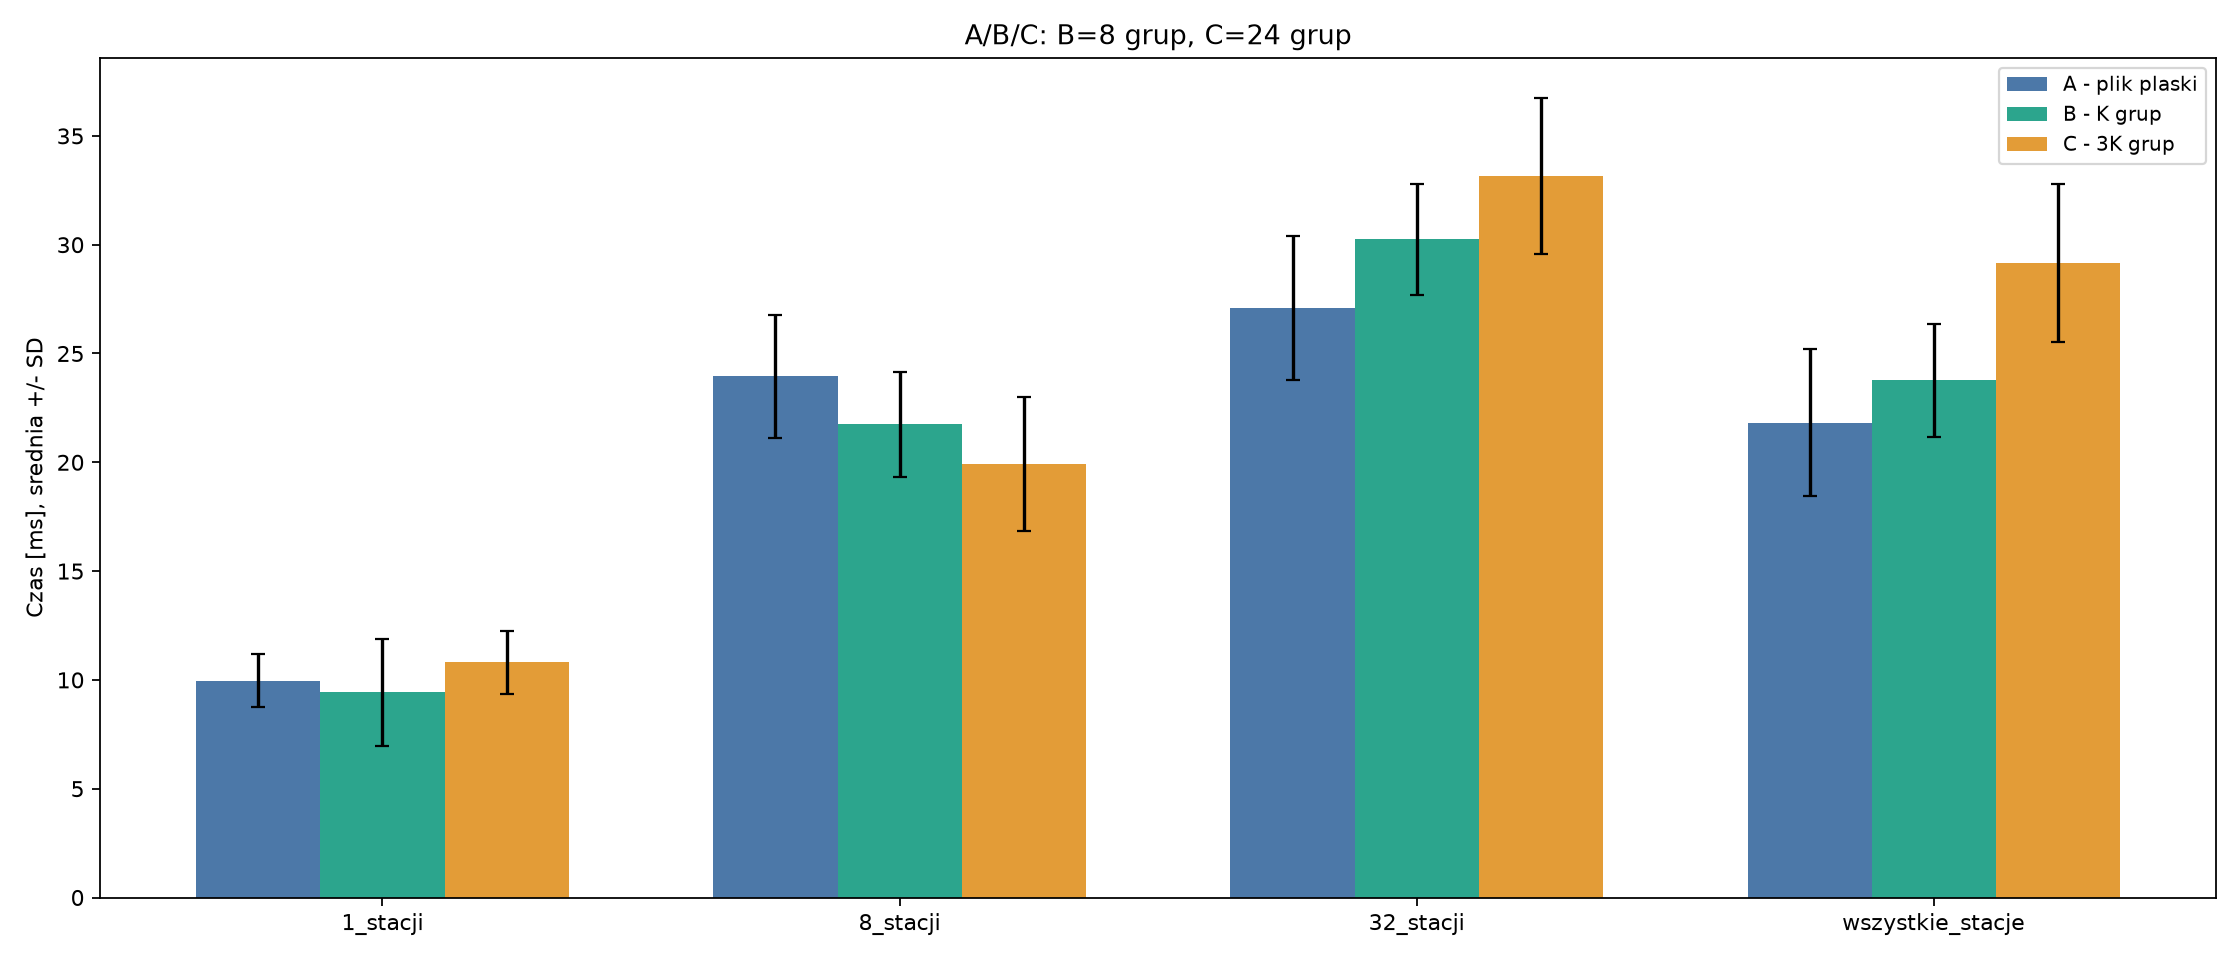

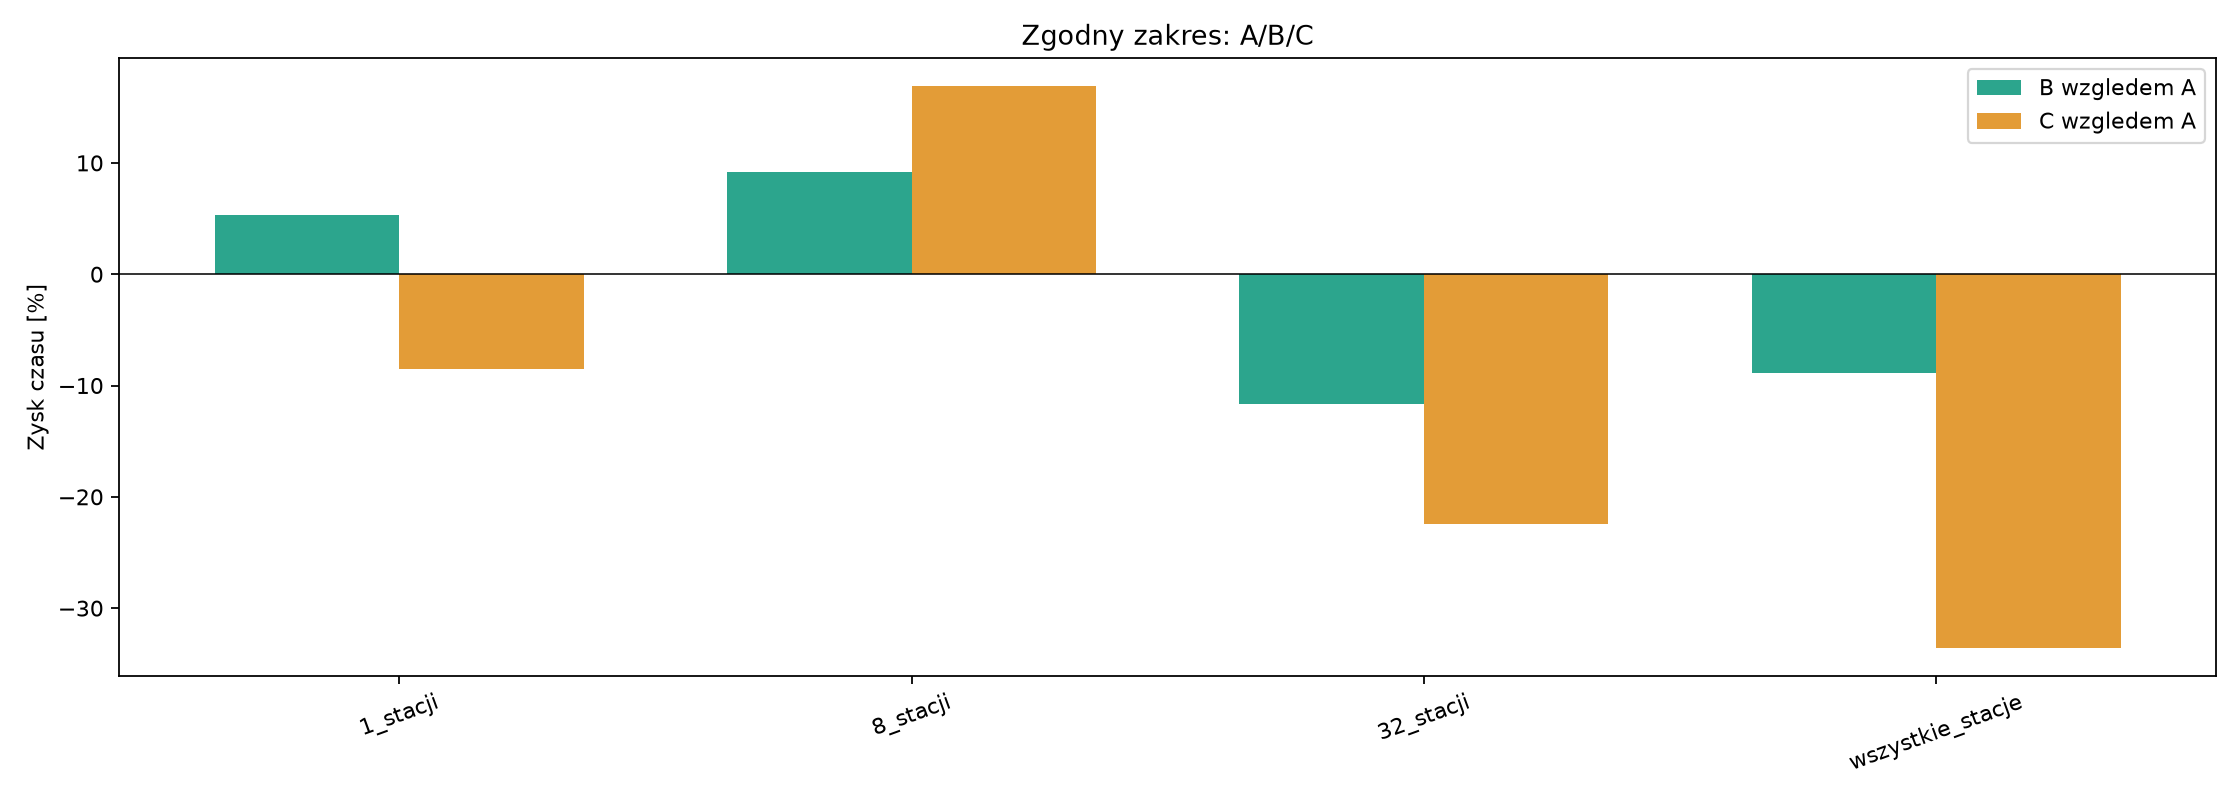

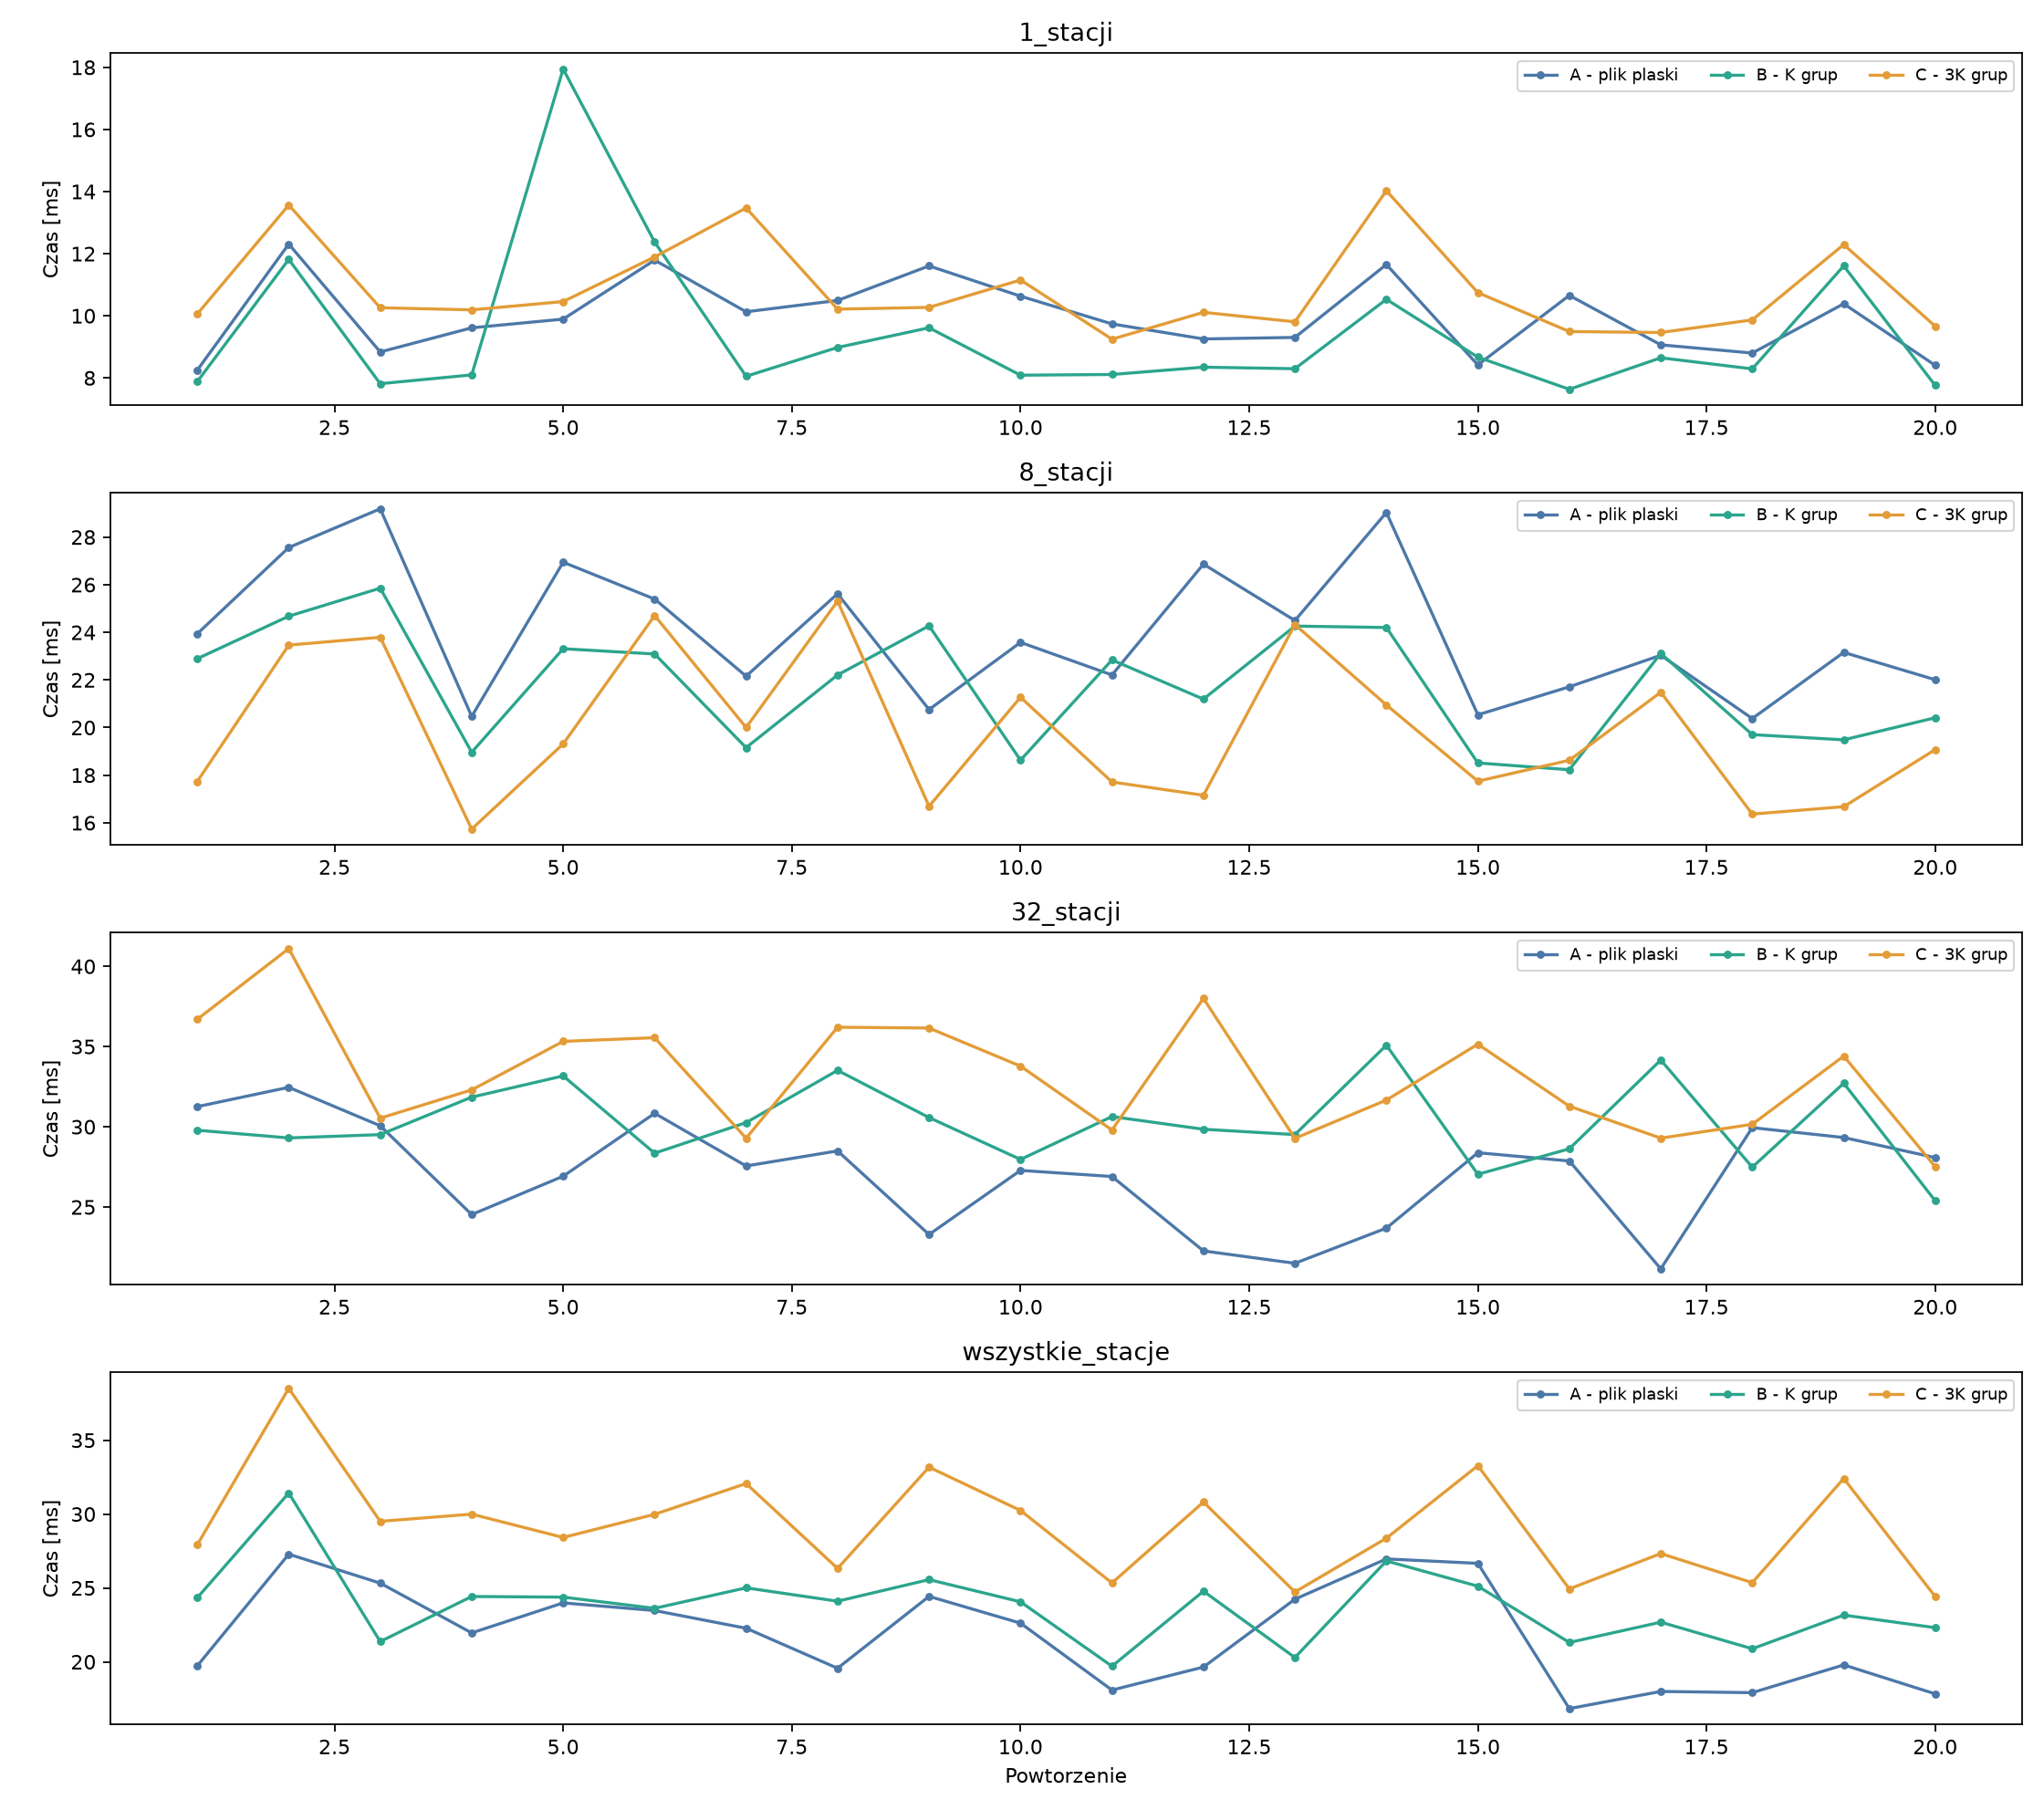

## Skala 10×

# Interpretacja wynikow

## Uklady danych

A: 8,432,640 wierszy, 1 plikow, 69 grup wierszy, 240.83 MB.

B: 8,432,640 wierszy, 8 plikow, 72 grup wierszy, 301.01 MB.

C: 8,432,640 wierszy, 24 plikow, 72 grup wierszy, 313.08 MB.

B grupuje cale stacje w niewielu partycjach, wyrownujac liczbe wierszy. Nie jest to gwarancja najlepszego podzialu: mniej plikow oznacza mniejszy narzut, ale dla jednej stacji trzeba przeczytac takze dane innych stacji z jej grupy.

B ma 8 grup stacji, C ma 24 grup. A/B/C obliczaja wynik dla tych samych stacji w kazdym scenariuszu.

Walidacja: quick. Tryb quick nie porownuje wszystkich wartosci i nie sprawdza unikalnosci kluczy calego zbioru. Zgodnosc agregacji sprawdzono osobno.

Ponowne wykorzystanie przygotowanych danych: False. Przygotowanie i walidacja nie wchodza do czasu zapytan.

Przyjeto prog niewielkiej zmiany 5% lub roznice srednich nieprzekraczajaca SD sparowanych roznic. To regula opisowa, nie test istotnosci. Cache OS nie byl czyszczony.

## 1_stacji

Wybrano 1 stacji; filtr B obejmuje 1 z 8 grup, filtr C 1 z 24 grup.

### B - K grup wzgledem A - plik plaski

Sredni czas: 12.726 ms vs 29.007 ms. Zysk czasu: +56.13%. SD sparowanych roznic: 3.609 ms.

Partycjonowanie skrocilo czas wzgledem pliku plaskiego dla tych samych stacji. Wynik jest zgodny z korzyscia z ograniczenia odczytu, jezeli plan potwierdza pruning. Wniosek dotyczy tego zakresu danych.

### C - 3K grup wzgledem A - plik plaski

Sredni czas: 12.156 ms vs 29.007 ms. Zysk czasu: +58.09%. SD sparowanych roznic: 3.090 ms.

Partycjonowanie skrocilo czas wzgledem pliku plaskiego dla tych samych stacji. Wynik jest zgodny z korzyscia z ograniczenia odczytu, jezeli plan potwierdza pruning. Wniosek dotyczy tego zakresu danych.

### B - K grup wzgledem C - 3K grup

Sredni czas: 12.726 ms vs 12.156 ms. Zysk czasu: -4.69%. SD sparowanych roznic: 2.029 ms.

Roznica jest niewielka lub porownywalna z rozrzutem pomiarow. Nie ma podstaw, by na tej serii uznac przewage za wyrazna i stabilna. Warto powtorzyc test w stalych warunkach.

## 8_stacji

Wybrano 8 stacji; filtr B obejmuje 5 z 8 grup, filtr C 7 z 24 grup.

### B - K grup wzgledem A - plik plaski

Sredni czas: 91.337 ms vs 149.974 ms. Zysk czasu: +39.10%. SD sparowanych roznic: 12.771 ms.

Partycjonowanie skrocilo czas wzgledem pliku plaskiego dla tych samych stacji. Wynik jest zgodny z korzyscia z ograniczenia odczytu, jezeli plan potwierdza pruning. Wniosek dotyczy tego zakresu danych.

### C - 3K grup wzgledem A - plik plaski

Sredni czas: 51.810 ms vs 149.974 ms. Zysk czasu: +65.45%. SD sparowanych roznic: 20.124 ms.

Partycjonowanie skrocilo czas wzgledem pliku plaskiego dla tych samych stacji. Wynik jest zgodny z korzyscia z ograniczenia odczytu, jezeli plan potwierdza pruning. Wniosek dotyczy tego zakresu danych.

### B - K grup wzgledem C - 3K grup

Sredni czas: 91.337 ms vs 51.810 ms. Zysk czasu: -76.29%. SD sparowanych roznic: 10.697 ms.

Mniejsza liczba grup B wydluzyla czas wzgledem wiekszej liczby grup C. Mozliwym powodem jest odczyt danych dodatkowych stacji w wybranych grupach; oszczednosc liczby plikow nie wystarczyla w tym pomiarze.

## 32_stacji

Wybrano 32 stacji; filtr B obejmuje 8 z 8 grup, filtr C 19 z 24 grup.

### B - K grup wzgledem A - plik plaski

Sredni czas: 139.421 ms vs 151.419 ms. Zysk czasu: +7.92%. SD sparowanych roznic: 13.157 ms.

Roznica jest niewielka lub porownywalna z rozrzutem pomiarow. Nie ma podstaw, by na tej serii uznac przewage za wyrazna i stabilna. Warto powtorzyc test w stalych warunkach.

### C - 3K grup wzgledem A - plik plaski

Sredni czas: 120.742 ms vs 151.419 ms. Zysk czasu: +20.26%. SD sparowanych roznic: 13.271 ms.

Partycjonowanie skrocilo czas wzgledem pliku plaskiego dla tych samych stacji. Wynik jest zgodny z korzyscia z ograniczenia odczytu, jezeli plan potwierdza pruning. Wniosek dotyczy tego zakresu danych.

### B - K grup wzgledem C - 3K grup

Sredni czas: 139.421 ms vs 120.742 ms. Zysk czasu: -15.47%. SD sparowanych roznic: 8.521 ms.

Mniejsza liczba grup B wydluzyla czas wzgledem wiekszej liczby grup C. Mozliwym powodem jest odczyt danych dodatkowych stacji w wybranych grupach; oszczednosc liczby plikow nie wystarczyla w tym pomiarze.

## wszystkie_stacje

### B - K grup wzgledem A - plik plaski

Sredni czas: 134.132 ms vs 142.883 ms. Zysk czasu: +6.12%. SD sparowanych roznic: 10.122 ms.

Roznica jest niewielka lub porownywalna z rozrzutem pomiarow. Nie ma podstaw, by na tej serii uznac przewage za wyrazna i stabilna. Warto powtorzyc test w stalych warunkach.

### C - 3K grup wzgledem A - plik plaski

Sredni czas: 137.861 ms vs 142.883 ms. Zysk czasu: +3.51%. SD sparowanych roznic: 12.781 ms.

Roznica jest niewielka lub porownywalna z rozrzutem pomiarow. Nie ma podstaw, by na tej serii uznac przewage za wyrazna i stabilna. Warto powtorzyc test w stalych warunkach.

### B - K grup wzgledem C - 3K grup

Sredni czas: 134.132 ms vs 137.861 ms. Zysk czasu: +2.70%. SD sparowanych roznic: 11.958 ms.

Roznica jest niewielka lub porownywalna z rozrzutem pomiarow. Nie ma podstaw, by na tej serii uznac przewage za wyrazna i stabilna. Warto powtorzyc test w stalych warunkach.

## Podsumowanie

B wzgledem A: poprawa w 2 scenariuszach, pogorszenie w 0, niewielka lub niestabilna roznica w 2.

C wzgledem A: poprawa w 3 scenariuszach, pogorszenie w 0, niewielka lub niestabilna roznica w 1.

Zmiana rozmiaru B wzgledem A: +24.99%.

Zmiana rozmiaru C wzgledem A: +30.00%.

Nie wyliczamy kosztow chmury ani fizycznie odczytanych bajtow na podstawie samego czasu. EXPLAIN pokazuje planowane filtry i pruning, nie pomiar fizycznego odczytu.

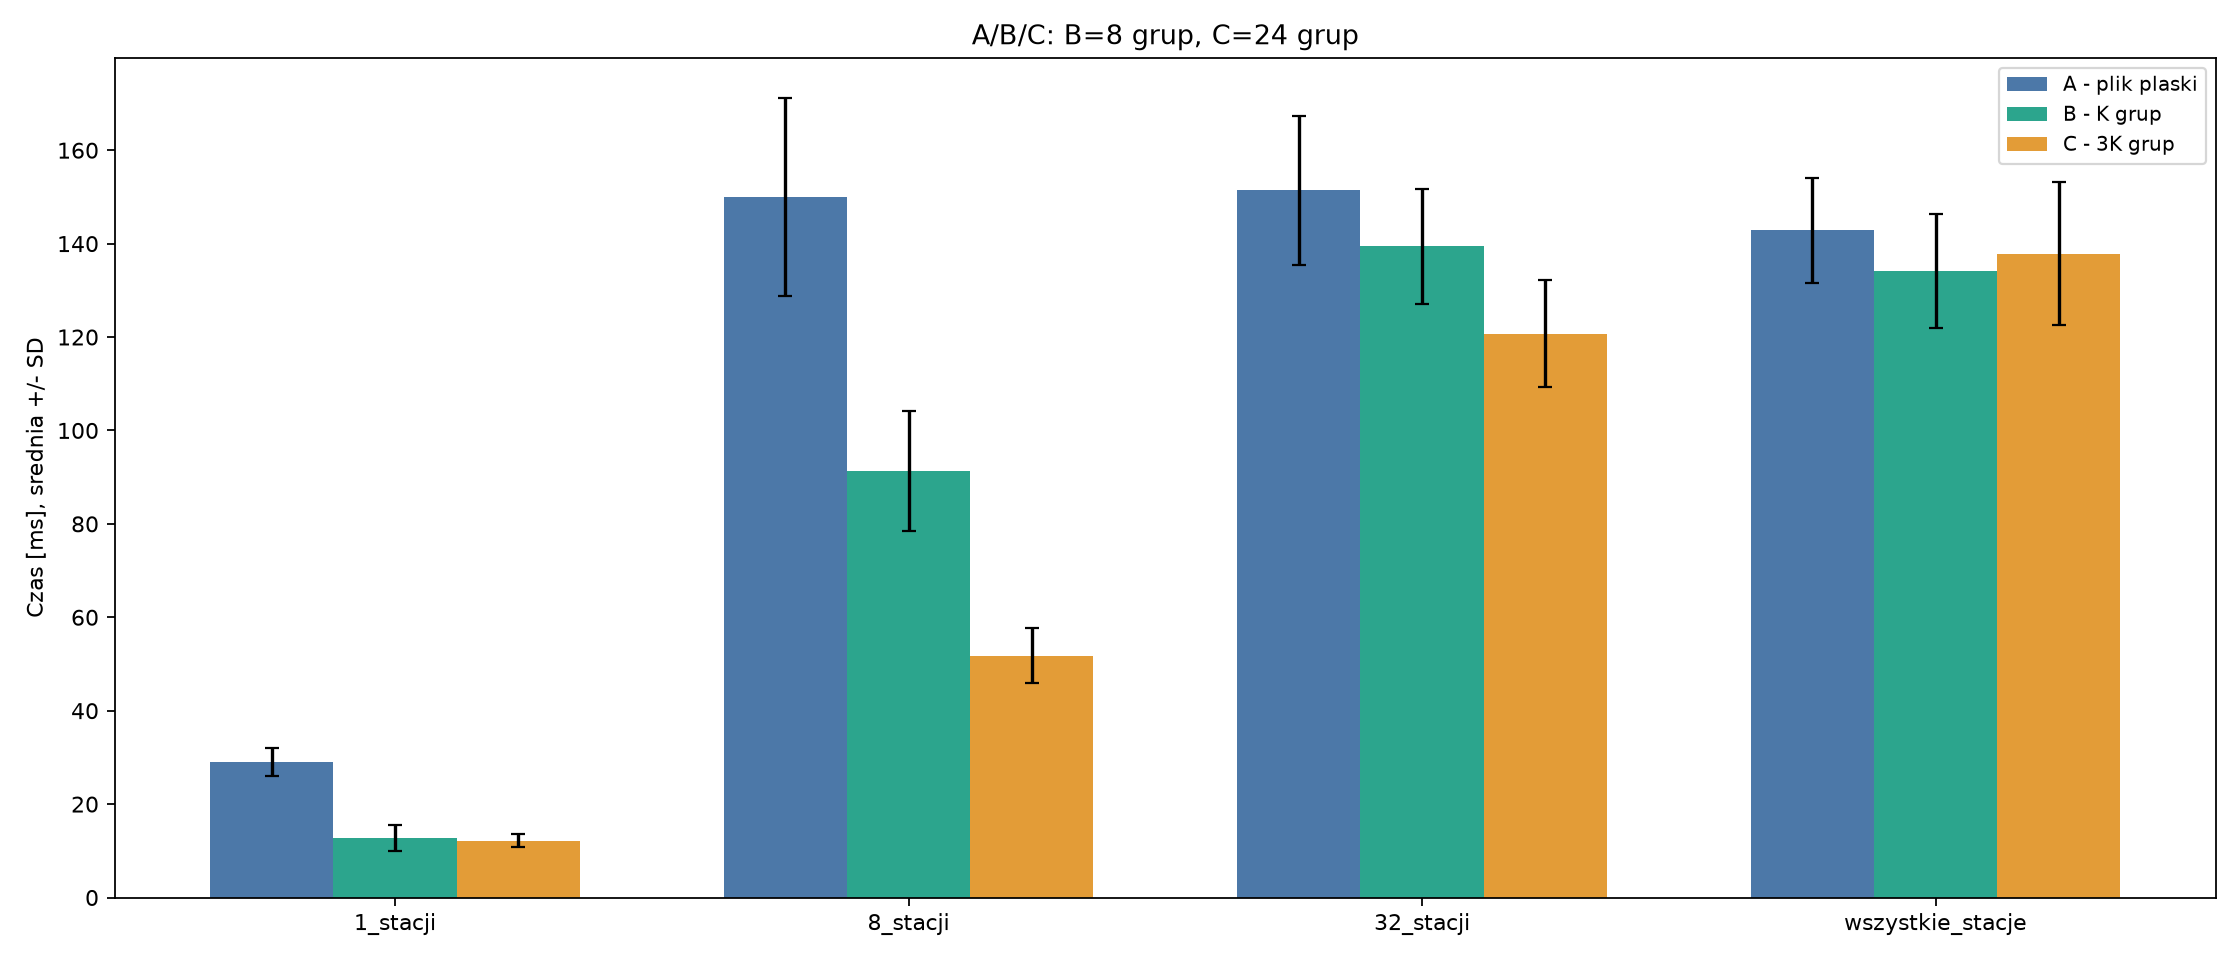

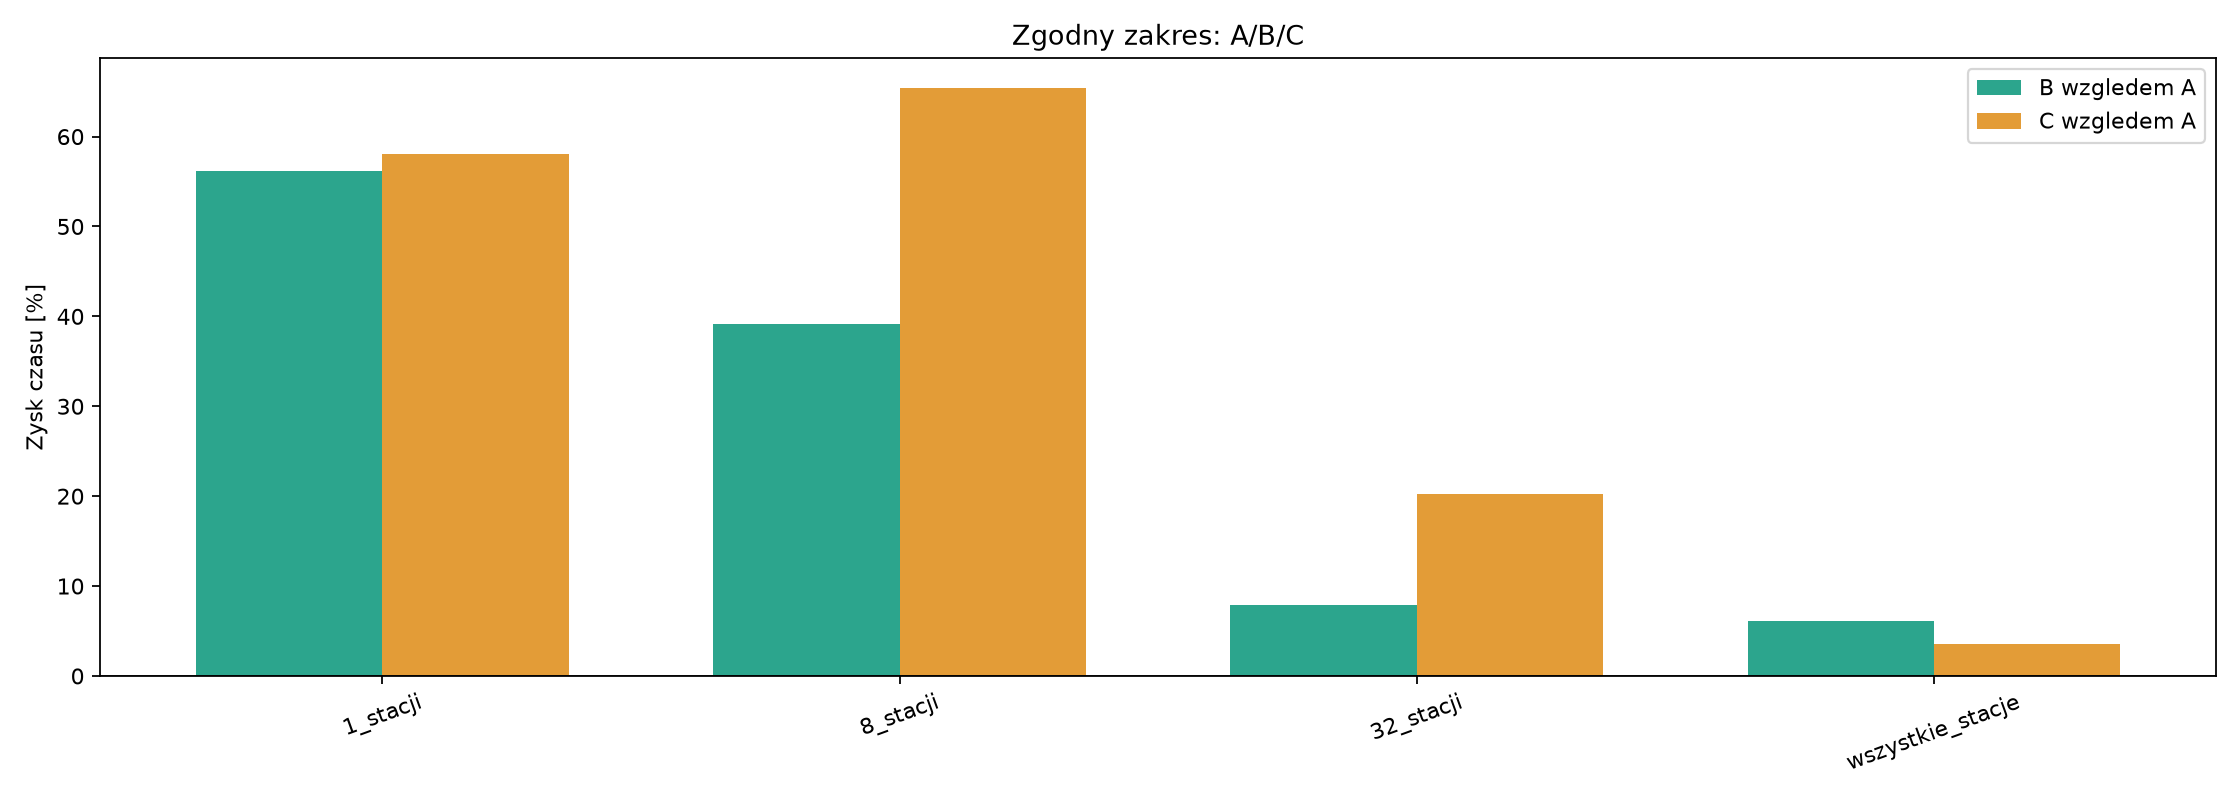

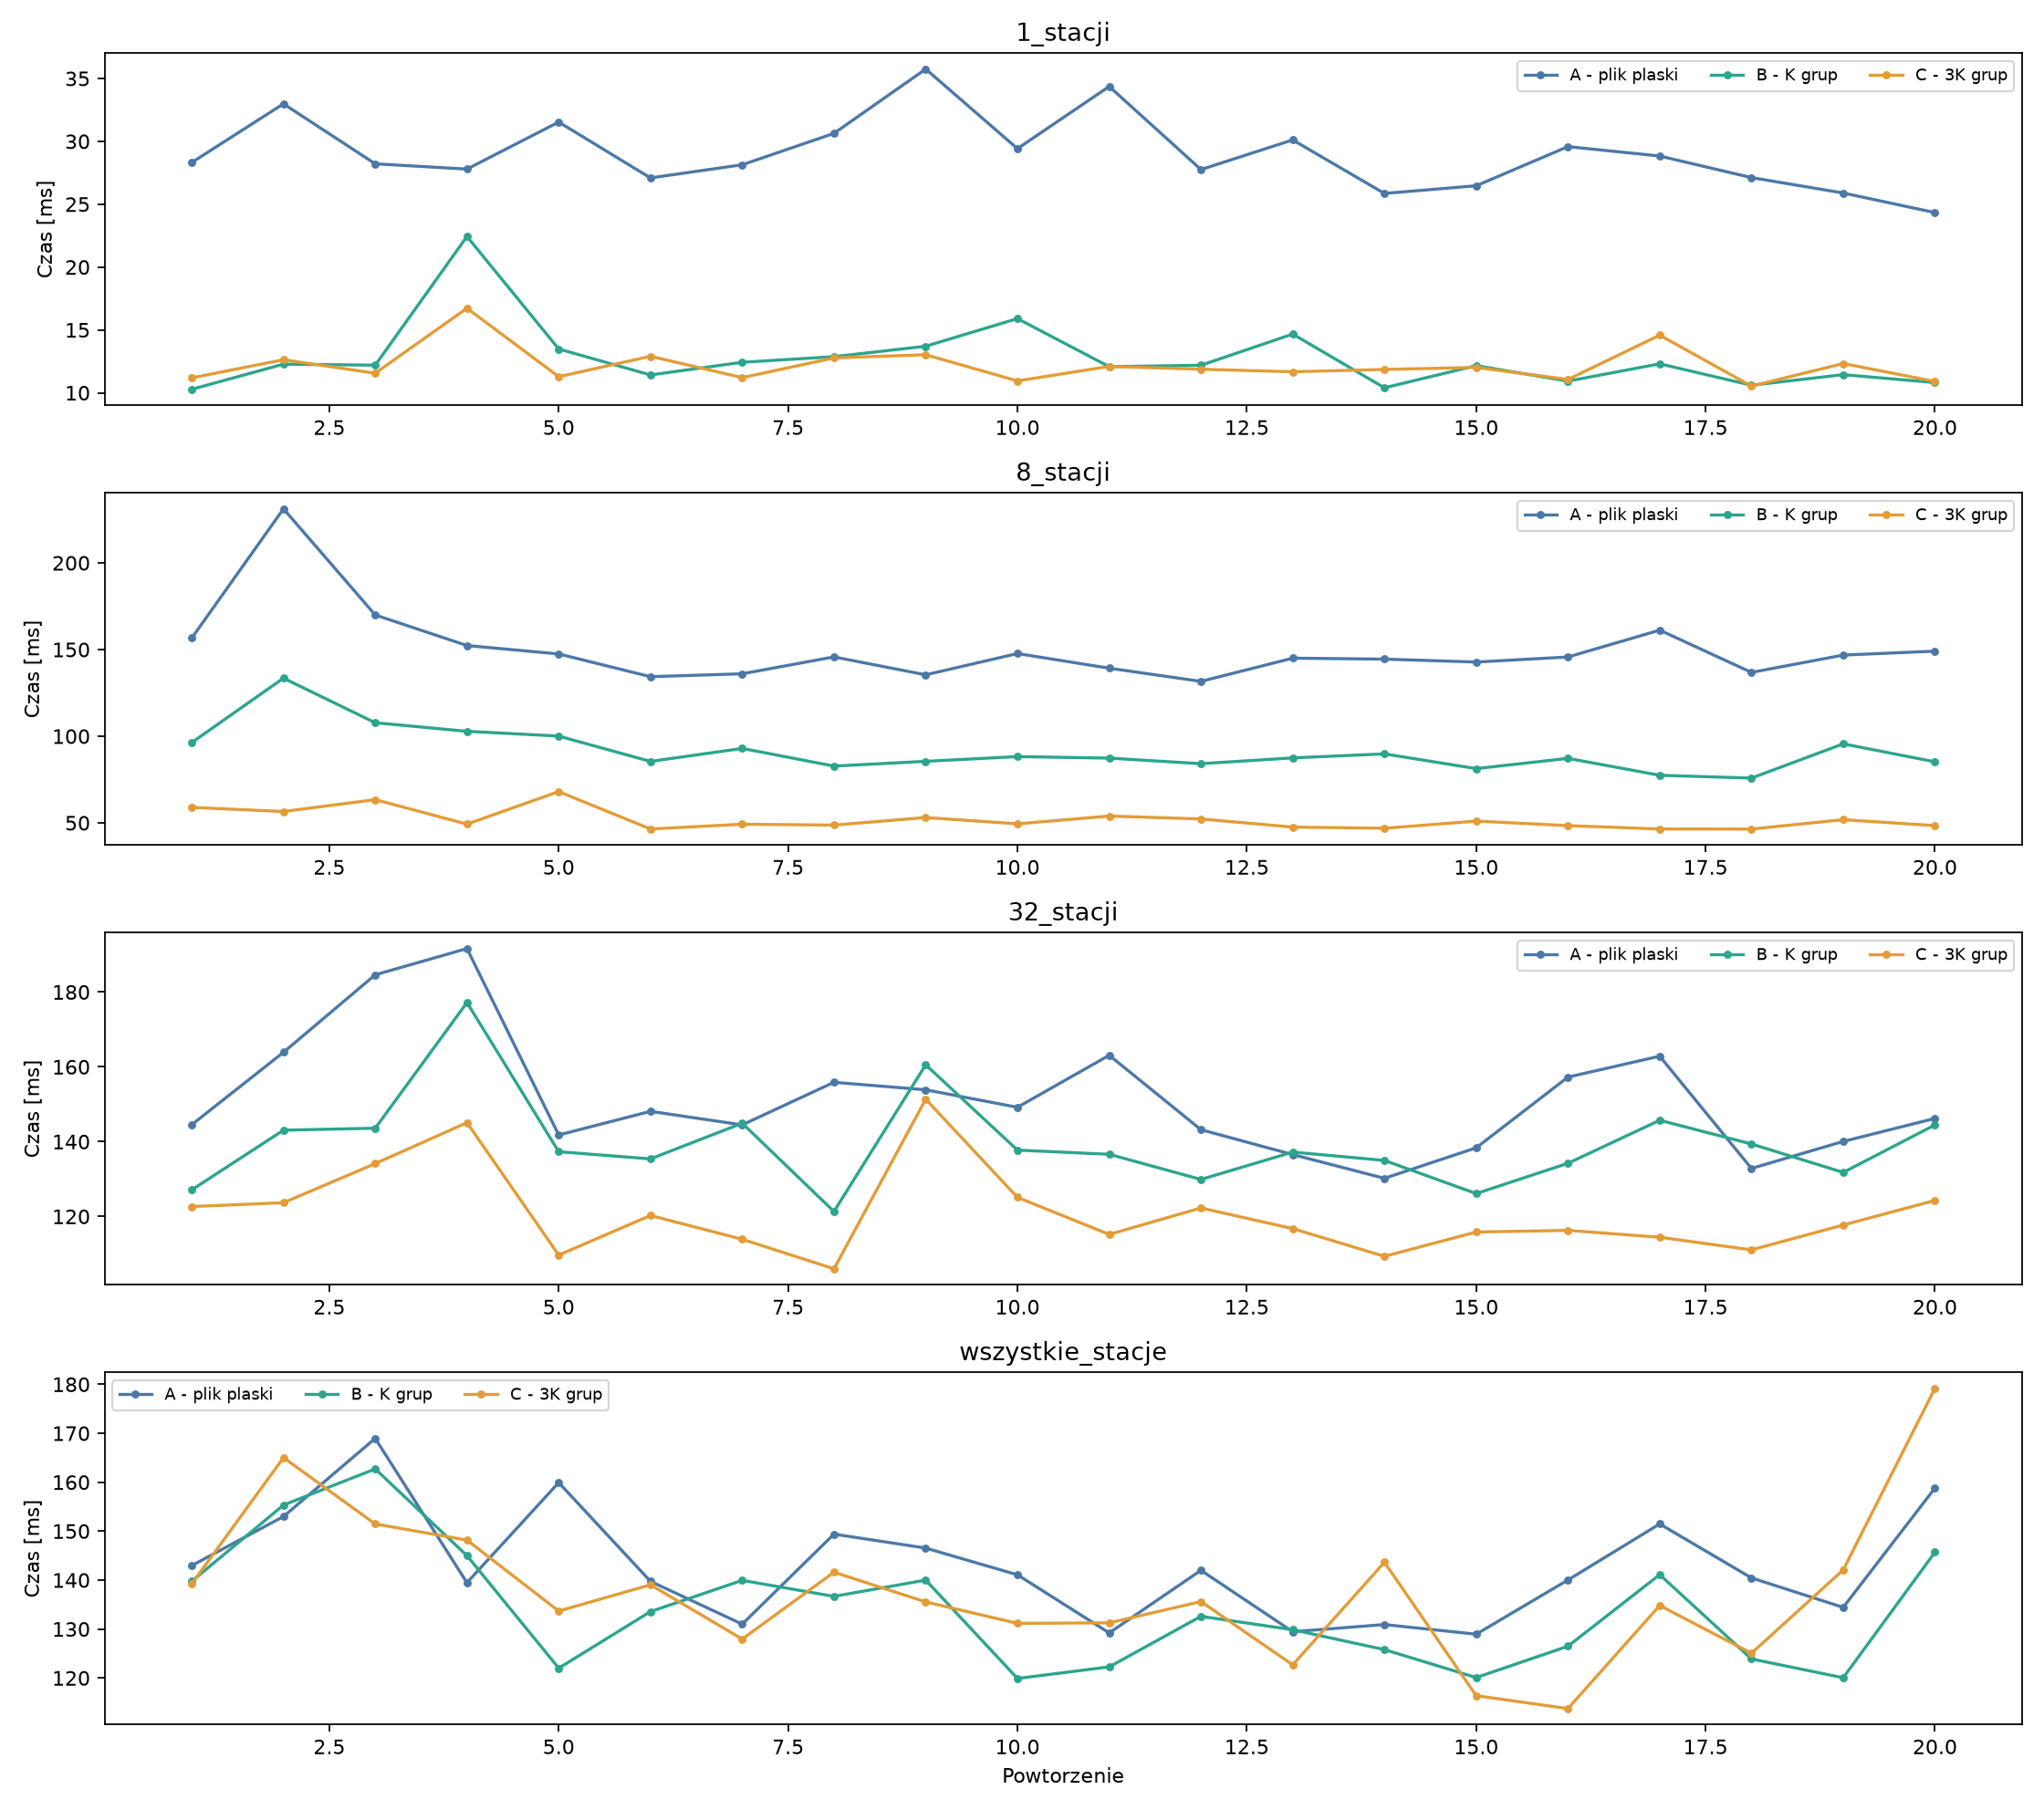

In [5]:
for result in results:
    display(Markdown(f"## Skala {result['scale_factor']}×"))
    display(Markdown((result["report"] / "interpretation.md").read_text(encoding="utf-8")))
    if SHOW_PLOTS:
        from IPython.display import Image
        for path in sorted(result["report"].glob("*.png")):
            display(Image(filename=str(path)))